In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from pathlib import Path
from PIL import Image
from keras.models import Sequential
from tensorflow.keras.models import load_model
from tensorflow.keras.layers import  Input, Conv2D, MaxPool2D, Flatten, Dense, BatchNormalization, GlobalAveragePooling2D
from tensorflow.keras.applications.vgg16 import VGG16
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.mobilenet_v2 import MobileNetV2
from tensorflow.keras.applications.resnet50 import preprocess_input 
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from keras import callbacks

In [2]:
train_dataset, validation_dataset = tf.keras.preprocessing.image_dataset_from_directory(
    "../data/training",
    image_size=(224, 224),
    seed = 42,
    validation_split = 0.2,
    subset = "both",
    batch_size=32,
    label_mode="binary"
)

test_dataset = tf.keras.preprocessing.image_dataset_from_directory(
    "../data/testing",
    image_size=(224, 224),
    shuffle=False,
    batch_size=32,
    label_mode="binary"
)

Found 2392 files belonging to 2 classes.
Using 1914 files for training.
Using 478 files for validation.
Found 597 files belonging to 2 classes.


In [3]:
model = Sequential()
model.add(Input(shape=(224, 224, 3)))
model.add(Flatten())
model.add(Dense(10, activation='relu'))
model.add(Dense(10, activation='relu'))
model.add(Dense(1, activation="sigmoid"))

model.compile(optimizer='adam',
              loss='binary_crossentropy', 
              metrics=[
                      tf.keras.metrics.BinaryAccuracy(name="accuracy"),
                      tf.keras.metrics.Precision(name="precision"),
                      tf.keras.metrics.Recall(name="recall"),
                      tf.keras.metrics.F1Score(threshold=0.5, name="f1"),
                      tf.keras.metrics.AUC(curve="ROC", name="roc_auc"),
                      tf.keras.metrics.AUC(curve="PR", name="pr_auc")
                  ])

history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=4
)
results = model.evaluate(test_dataset, return_dict=True)
print(results)

Epoch 1/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 27s 363ms/step - accuracy: 0.5084 - f1: 0.6228 - loss: 766.2148 - pr_auc: 0.5202 - precision: 0.5125 - recall: 0.7937 - roc_auc: 0.5094 - val_accuracy: 0.5251 - val_f1: 0.6886 - val_loss: 0.6929 - val_pr_auc: 0.5251 - val_precision: 0.5251 - val_recall: 1.0000 - val_roc_auc: 0.5000
Epoch 2/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 21s 347ms/step - accuracy: 0.5115 - f1: 0.6768 - loss: 0.6931 - pr_auc: 0.5045 - precision: 0.5115 - recall: 1.0000 - roc_auc: 0.4881 - val_accuracy: 0.5251 - val_f1: 0.6886 - val_loss: 0.6929 - val_pr_auc: 0.5251 - val_precision: 0.5251 - val_recall: 1.0000 - val_roc_auc: 0.5000
Epoch 3/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 44s 390ms/step - accuracy: 0.5115 - f1: 0.6768 - loss: 0.6930 - pr_auc: 0.5115 - precision: 0.5115 - recall: 1.0000 - roc_auc: 0.5000 - val_accuracy: 0.5251 - val_f1: 0.6886 - val_loss: 0.6927 - val_pr_auc: 0.5251 - val_precision: 0.5251 - val_recall: 1.0000 - val_roc_auc: 0.5000
Epoch 4/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 38s 339

In [ ]:
model = Sequential()
model.add(Input(shape=(224, 224, 3)))

model.add(Conv2D(16, kernel_size=3, 
                 activation='relu', 
                 padding='same'))
model.add(BatchNormalization())
model.add(MaxPool2D(2))
model.add(Conv2D(32, kernel_size=3, activation='relu',padding='same'))
model.add(MaxPool2D(2))
model.add(Conv2D(64, kernel_size=3, activation='relu',padding='same'))
model.add(MaxPool2D(2))
model.add(Flatten())
model.add(Dense(1, activation="sigmoid"))

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.F1Score(threshold=0.5, name="f1"),
        tf.keras.metrics.AUC(curve="ROC", name="roc_auc"),
        tf.keras.metrics.AUC(curve="PR", name="pr_auc")
    ]
)

history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=4
)
custom_model_results = model.evaluate(test_dataset, return_dict=True)
print(custom_model_results)

Epoch 1/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 127s 2s/step - accuracy: 0.7111 - f1: 0.7220 - loss: 0.6571 - pr_auc: 0.7426 - precision: 0.7109 - recall: 0.7334 - roc_auc: 0.7640 - val_accuracy: 0.5251 - val_f1: 0.6886 - val_loss: 5.1087 - val_pr_auc: 0.5251 - val_precision: 0.5251 - val_recall: 1.0000 - val_roc_auc: 0.5000
Epoch 2/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 121s 2s/step - accuracy: 0.9185 - f1: 0.9207 - loss: 0.2006 - pr_auc: 0.9779 - precision: 0.9161 - recall: 0.9254 - roc_auc: 0.9768 - val_accuracy: 0.5251 - val_f1: 0.6886 - val_loss: 3.6160 - val_pr_auc: 0.5718 - val_precision: 0.5251 - val_recall: 1.0000 - val_roc_auc: 0.5859
Epoch 3/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 130s 2s/step - accuracy: 0.9754 - f1: 0.9762 - loss: 0.0751 - pr_auc: 0.9969 - precision: 0.9688 - recall: 0.9837 - roc_auc: 0.9970 - val_accuracy: 0.8368 - val_f1: 0.8655 - val_loss: 0.3906 - val_pr_auc: 0.9893 - val_precision: 0.7629 - val_recall: 1.0000 - val_roc_auc: 0.9929
Epoch 4/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 142s 2s/step - 

In [5]:
custom_model_results = model.evaluate(test_dataset, return_dict=True)
print(custom_model_results)

19/19 ━━━━━━━━━━━━━━━━━━━━ 10s 528ms/step - accuracy: 0.9765 - f1: 0.9770 - loss: 0.0649 - pr_auc: 0.9991 - precision: 0.9835 - recall: 0.9707 - roc_auc: 0.9990         
{'accuracy': 0.9765493869781494, 'f1': 0.9770491123199463, 'loss': 0.06486256420612335, 'pr_auc': 0.9990777969360352, 'precision': 0.9834983348846436, 'recall': 0.9706840515136719, 'roc_auc': 0.9990003108978271}


In [6]:
model.save("../models/custom_model.keras")
baseline_model = load_model("../models/custom_model.keras")
baseline_model.summary()
model.count_params()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 16)   │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 50176)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │        50,177 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 221,413 (864.90 KB)

 Trainable params: 73,793 (288.25 KB)

 Non-trainable params: 32 (128.00 B)

 Optimizer params: 147,588 (576.52 KB)

73825

In [7]:
path = Path("../models/custom_model.keras")
custom_model_file_size = round(path.stat().st_size / (1024**2),2)
custom_model_params = model.count_params()

In [8]:
print(train_dataset.class_names)

['flip', 'notflip']


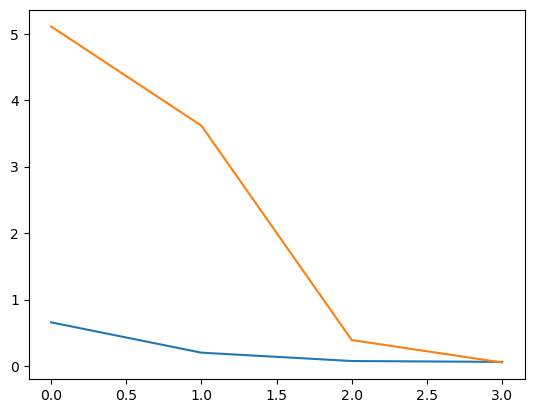

In [9]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])

plt.show()

In [10]:
resnet50_base_model = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Keep its pretrained weights fixed
resnet50_base_model.trainable = False

resnet50_model = Sequential()
resnet50_model.add(Input(shape=(224, 224, 3)))
resnet50_model.add(tf.keras.layers.Lambda(preprocess_input))
resnet50_model.add(resnet50_base_model)
resnet50_model.add(GlobalAveragePooling2D())
resnet50_model.add(Dense(1, activation="sigmoid"))

resnet50_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
            tf.keras.metrics.BinaryAccuracy(name="accuracy"),
            tf.keras.metrics.Precision(name="precision"),
            tf.keras.metrics.Recall(name="recall"),
            tf.keras.metrics.F1Score(threshold=0.5, name="f1"),
            tf.keras.metrics.AUC(curve="ROC", name="roc_auc"),
            tf.keras.metrics.AUC(curve="PR", name="pr_auc")
        ]
)

resnet50_model_history = resnet50_model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=4
)


Epoch 1/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 541s 9s/step - accuracy: 0.5272 - f1: 0.5284 - loss: 0.7151 - pr_auc: 0.5260 - precision: 0.5394 - recall: 0.5179 - roc_auc: 0.5257 - val_accuracy: 0.4958 - val_f1: 0.1831 - val_loss: 0.6863 - val_pr_auc: 0.6490 - val_precision: 0.6136 - val_recall: 0.1076 - val_roc_auc: 0.6749
Epoch 2/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 689s 11s/step - accuracy: 0.6061 - f1: 0.6089 - loss: 0.6779 - pr_auc: 0.6087 - precision: 0.6185 - recall: 0.5996 - roc_auc: 0.6350 - val_accuracy: 0.5900 - val_f1: 0.4201 - val_loss: 0.6771 - val_pr_auc: 0.7420 - val_precision: 0.8161 - val_recall: 0.2829 - val_roc_auc: 0.7179
Epoch 3/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 714s 12s/step - accuracy: 0.6390 - f1: 0.6581 - loss: 0.6608 - pr_auc: 0.6980 - precision: 0.6382 - recall: 0.6793 - roc_auc: 0.6875 - val_accuracy: 0.5481 - val_f1: 0.6992 - val_loss: 0.6737 - val_pr_auc: 0.7666 - val_precision: 0.5375 - val_recall: 1.0000 - val_roc_auc: 0.7237
Epoch 4/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 628s 10s/ste

In [11]:
resnet50_results = resnet50_model.evaluate(test_dataset, return_dict=True)
print(resnet50_results)

19/19 ━━━━━━━━━━━━━━━━━━━━ 103s 5s/step - accuracy: 0.6382 - f1: 0.6814 - loss: 0.6458 - pr_auc: 0.7721 - precision: 0.6226 - recall: 0.7524 - roc_auc: 0.7519       
{'accuracy': 0.6381909251213074, 'f1': 0.681415855884552, 'loss': 0.6458132863044739, 'pr_auc': 0.7721281051635742, 'precision': 0.6226415038108826, 'recall': 0.7524430155754089, 'roc_auc': 0.7518813610076904}


In [12]:
resnet50_model.save("../models/resnet50_model.keras")
path = Path("../models/resnet50_model.keras")
resnet50_file_size = round(path.stat().st_size / (1024**2),2)
resnet50_params = resnet50_model.count_params()

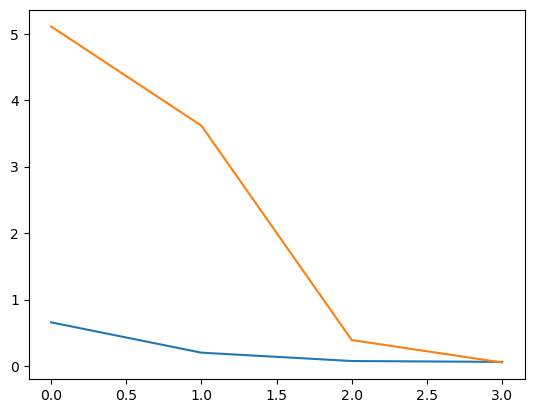

In [ ]:
plt.plot(resnet50_model_history.history['loss'])
plt.plot(resnet50_model_history.history['val_loss'])

plt.show()

In [ ]:
vgg16_base_model =  VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

vgg16_base_model.trainable = False

vgg16_model = Sequential()
vgg16_model.add(Input(shape=(224, 224, 3)))
vgg16_model.add(tf.keras.layers.Lambda(preprocess_input))
vgg16_model.add(vgg16_base_model)
vgg16_model.add(GlobalAveragePooling2D())
vgg16_model.add(Dense(1, activation="sigmoid"))

vgg16_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
            tf.keras.metrics.BinaryAccuracy(name="accuracy"),
            tf.keras.metrics.Precision(name="precision"),
            tf.keras.metrics.Recall(name="recall"),
            tf.keras.metrics.F1Score(threshold=0.5, name="f1"),
            tf.keras.metrics.AUC(curve="ROC", name="roc_auc"),
            tf.keras.metrics.AUC(curve="PR", name="pr_auc")
        ]
)
vgg16_model_history = vgg16_model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=4
)

vgg16_results = vgg16_model.evaluate(test_dataset, return_dict=True)
print(vgg16_results)

Epoch 1/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 1217s 20s/step - accuracy: 0.6014 - f1: 0.6472 - loss: 0.6782 - pr_auc: 0.6255 - precision: 0.5912 - recall: 0.7150 - roc_auc: 0.6387 - val_accuracy: 0.6548 - val_f1: 0.6421 - val_loss: 0.6636 - val_pr_auc: 0.7410 - val_precision: 0.7048 - val_recall: 0.5896 - val_roc_auc: 0.7334
Epoch 2/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 1111s 19s/step - accuracy: 0.6703 - f1: 0.6865 - loss: 0.6438 - pr_auc: 0.7745 - precision: 0.6683 - recall: 0.7058 - roc_auc: 0.7653 - val_accuracy: 0.6297 - val_f1: 0.6366 - val_loss: 0.6370 - val_pr_auc: 0.8153 - val_precision: 0.6568 - val_recall: 0.6175 - val_roc_auc: 0.7731
Epoch 3/4
29/60 ━━━━━━━━━━━━━━━━━━━━ 13:22 26s/step - accuracy: 0.6570 - f1: 0.6691 - loss: 0.6269 - pr_auc: 0.8210 - precision: 0.6480 - recall: 0.6971 - roc_auc: 0.7931

In [ ]:
vgg16_model.save("../models/vgg16_model.keras")
path = Path("../models/vgg16_model.keras")
vgg16_file_size = round(path.stat().st_size / (1024**2),2)
vgg16_params = vgg16_model.count_params()

File size: 56.22 MB


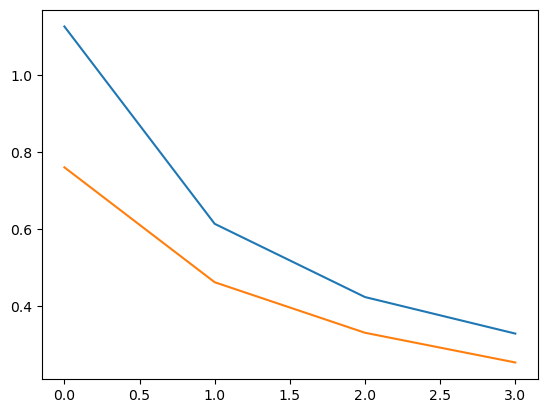

In [ ]:
plt.plot(vgg16_model_history.history['loss'])
plt.plot(vgg16_model_history.history['val_loss'])

plt.show()

In [ ]:
vgg16_base_model =  VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

augmentation_model = Sequential([
    #tf.keras.layers.RandomRotation(0.02),
    #tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomContrast(0.1)
])

vgg16_base_model.trainable = False

vgg16_aug_model = Sequential()
vgg16_aug_model.add(Input(shape=(224, 224, 3)))
vgg16_aug_model.add(augmentation_model)
vgg16_aug_model.add(tf.keras.layers.Lambda(preprocess_input))
vgg16_aug_model.add(vgg16_base_model)
vgg16_aug_model.add(GlobalAveragePooling2D())
vgg16_aug_model.add(Dense(1, activation="sigmoid"))

vgg16_aug_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
            tf.keras.metrics.BinaryAccuracy(name="accuracy"),
            tf.keras.metrics.Precision(name="precision"),
            tf.keras.metrics.Recall(name="recall"),
            tf.keras.metrics.F1Score(threshold=0.5, name="f1"),
            tf.keras.metrics.AUC(curve="ROC", name="roc_auc"),
            tf.keras.metrics.AUC(curve="PR", name="pr_auc")
        ]
)
vgg16_aug_model_history = vgg16_aug_model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=4
)

vgg16_aug_model_results = vgg16_aug_model.evaluate(test_dataset, return_dict=True)
print(vgg16_aug_model_results)

In [ ]:
vgg16_aug_model.save("../models/vgg16_aug_model.keras")
path = Path("../models/vgg16_aug_model.keras")
vgg16_aug_file_size = round(path.stat().st_size / (1024**2),2)
vgg16_aug_params = vgg16_aug_model.count_params()

In [ ]:
efficientnetb0_base_model = EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

efficientnetb0_base_model.trainable = False

efficientnetb0_model = Sequential()
efficientnetb0_model.add(Input(shape=(224, 224, 3)))
efficientnetb0_model.add(efficientnetb0_base_model)
efficientnetb0_model.add(GlobalAveragePooling2D())
efficientnetb0_model.add(Dense(1, activation="sigmoid"))

efficientnetb0_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
            tf.keras.metrics.BinaryAccuracy(name="accuracy"),
            tf.keras.metrics.Precision(name="precision"),
            tf.keras.metrics.Recall(name="recall"),
            tf.keras.metrics.F1Score(threshold=0.5, name="f1"),
            tf.keras.metrics.AUC(curve="ROC", name="roc_auc"),
            tf.keras.metrics.AUC(curve="PR", name="pr_auc")
        ]
)
efficientnetb0_model_history = efficientnetb0_model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=4
)

efficientnetb0_results = efficientnetb0_model.evaluate(test_dataset, return_dict=True)
print(efficientnetb0_results)

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 438s 7s/step - accuracy: 0.6661 - f1: 0.6918 - loss: 0.6136 - pr_auc: 0.7022 - precision: 0.6554 - recall: 0.7324 - roc_auc: 0.7316 - val_accuracy: 0.8347 - val_f1: 0.8597 - val_loss: 0.5104 - val_pr_auc: 0.8735 - val_precision: 0.7756 - val_recall: 0.9641 - val_roc_auc: 0.9047
Epoch 2/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 352s 6s/step - accuracy: 0.8464 - f1: 0.8599 - loss: 0.4613 - pr_auc: 0.9126 - precision: 0.8061 - recall: 0.9213 - roc_auc: 0.9232 - val_accuracy: 0.8975 - val_f1: 0.9070 - val_loss: 0.4028 - val_pr_auc: 0.9654 - val_precision: 0.8659 - val_recall: 0.9522 - val_roc_auc: 0.9676
Epoch 3/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 309s 5s/step - accuracy: 0.8887 - f1: 0.8972 - loss: 0.3808 - pr_auc: 0.9548 - precision: 0.8507 - recall: 0.9489 - roc_auc: 0.9570 - val_accuracy: 0.9079 - val_f1: 0.9179 - val_loss: 0.3394 - val_pr_auc: 0.9801 - val_precision: 0.8632 - val_recall: 0.9801 - val_roc_auc: 0.9791
E

In [ ]:
efficientnetb0_model.save("../models/efficientnetb0_model.keras")
path = Path("../models/efficientnetb0_model.keras")
efficientnetb0_file_size = round(path.stat().st_size / (1024**2),2)
efficientnetb0_params = efficientnetb0_model.count_params()

File size: 16.27 MB


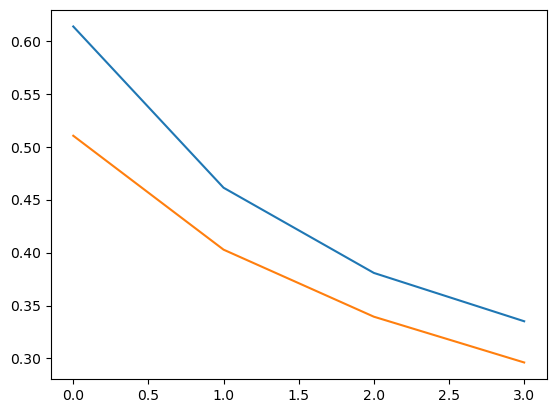

In [ ]:
plt.plot(efficientnetb0_model_history.history['loss'])
plt.plot(efficientnetb0_model_history.history['val_loss'])

plt.show()

In [ ]:
mobilenetv2_base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

mobilenetv2_base_model.trainable = False

mobilenetv2_model = Sequential()
mobilenetv2_model.add(Input(shape=(224, 224, 3)))
mobilenetv2_model.add(tf.keras.layers.Lambda(preprocess_input))
mobilenetv2_model.add(mobilenetv2_base_model)
mobilenetv2_model.add(GlobalAveragePooling2D())
mobilenetv2_model.add(Dense(1, activation="sigmoid"))

mobilenetv2_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
            tf.keras.metrics.BinaryAccuracy(name="accuracy"),
            tf.keras.metrics.Precision(name="precision"),
            tf.keras.metrics.Recall(name="recall"),
            tf.keras.metrics.F1Score(threshold=0.5, name="f1"),
            tf.keras.metrics.AUC(curve="ROC", name="roc_auc"),
            tf.keras.metrics.AUC(curve="PR", name="pr_auc")
        ]
)
mobilenetv2_model_history = mobilenetv2_model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=4
)

mobilenetv2_results = mobilenetv2_model.evaluate(test_dataset, return_dict=True)
print(mobilenetv2_results)


Epoch 1/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 304s 5s/step - accuracy: 0.7017 - f1: 0.7152 - loss: 0.5674 - pr_auc: 0.7785 - precision: 0.6988 - recall: 0.7324 - roc_auc: 0.7810 - val_accuracy: 0.7657 - val_f1: 0.7879 - val_loss: 0.4941 - val_pr_auc: 0.8830 - val_precision: 0.7509 - val_recall: 0.8287 - val_roc_auc: 0.8660
Epoch 2/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 251s 4s/step - accuracy: 0.8333 - f1: 0.8429 - loss: 0.4206 - pr_auc: 0.9171 - precision: 0.8137 - recall: 0.8744 - roc_auc: 0.9165 - val_accuracy: 0.7929 - val_f1: 0.8278 - val_loss: 0.4298 - val_pr_auc: 0.9344 - val_precision: 0.7346 - val_recall: 0.9482 - val_roc_auc: 0.9232
Epoch 3/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 242s 4s/step - accuracy: 0.8689 - f1: 0.8763 - loss: 0.3586 - pr_auc: 0.9445 - precision: 0.8467 - recall: 0.9081 - roc_auc: 0.9445 - val_accuracy: 0.8577 - val_f1: 0.8722 - val_loss: 0.3585 - val_pr_auc: 0.9555 - val_precision: 0.8256 - val_recall: 0.9243 - val_roc_auc: 0.9481
Epoch 4/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 161s 3s/step -

In [ ]:
mobilenetv2_model.save("../models/mobilenetv2_model.keras")
path = Path("../models/mobilenetv2_model.keras")
mobilenetv2_file_size = round(path.stat().st_size / (1024**2),2)
mobilenetv2_params = mobilenetv2_model.count_params()

File size: 9.19 MB


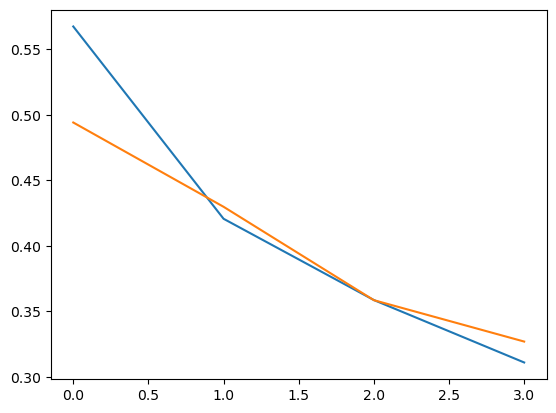

In [ ]:
plt.plot(mobilenetv2_model_history.history['loss'])
plt.plot(mobilenetv2_model_history.history['val_loss'])

plt.show()

In [ ]:
mobilenetv2_base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

mobilenetv2_base_model.trainable = True


for layer in mobilenetv2_base_model.layers[:-20]:
    layer.trainable = False


mobilenetv2_tuned_model = Sequential()
mobilenetv2_tuned_model.add(Input(shape=(224, 224, 3)))
mobilenetv2_tuned_model.add(tf.keras.layers.Lambda(preprocess_input))
mobilenetv2_tuned_model.add(mobilenetv2_base_model)
mobilenetv2_tuned_model.add(GlobalAveragePooling2D())
mobilenetv2_tuned_model.add(Dense(1, activation="sigmoid"))

mobilenetv2_tuned_model.compile(
    optimizer= tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="binary_crossentropy",
    metrics=[
            tf.keras.metrics.BinaryAccuracy(name="accuracy"),
            tf.keras.metrics.Precision(name="precision"),
            tf.keras.metrics.Recall(name="recall"),
            tf.keras.metrics.F1Score(threshold=0.5, name="f1"),
            tf.keras.metrics.AUC(curve="ROC", name="roc_auc"),
            tf.keras.metrics.AUC(curve="PR", name="pr_auc")
        ]
)

earlystopping = callbacks.EarlyStopping(monitor="val_loss",
                                        mode="min",
                                        patience=3,
                                        restore_best_weights=True)


mobilenetv2_tuned_model_history = mobilenetv2_tuned_model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=5,
    callbacks = [earlystopping]

)

Epoch 1/5
60/60 ━━━━━━━━━━━━━━━━━━━━ 389s 5s/step - accuracy: 0.7706 - f1: 0.7775 - loss: 0.5312 - pr_auc: 0.8381 - precision: 0.7716 - recall: 0.7835 - roc_auc: 0.8459 - val_accuracy: 0.7469 - val_f1: 0.7206 - val_loss: 0.5437 - val_pr_auc: 0.8905 - val_precision: 0.8571 - val_recall: 0.6215 - val_roc_auc: 0.8856
Epoch 2/5
60/60 ━━━━━━━━━━━━━━━━━━━━ 294s 4s/step - accuracy: 0.9138 - f1: 0.9177 - loss: 0.3447 - pr_auc: 0.9728 - precision: 0.8967 - recall: 0.9397 - roc_auc: 0.9730 - val_accuracy: 0.8661 - val_f1: 0.8667 - val_loss: 0.4336 - val_pr_auc: 0.9597 - val_precision: 0.9083 - val_recall: 0.8287 - val_roc_auc: 0.9552
Epoch 3/5
60/60 ━━━━━━━━━━━━━━━━━━━━ 299s 5s/step - accuracy: 0.9488 - f1: 0.9509 - loss: 0.2477 - pr_auc: 0.9894 - precision: 0.9340 - recall: 0.9683 - roc_auc: 0.9894 - val_accuracy: 0.9079 - val_f1: 0.9113 - val_loss: 0.3576 - val_pr_auc: 0.9779 - val_precision: 0.9224 - val_recall: 0.9004 - val_roc_auc: 0.9754
Epoch 4/5
60/60 ━━━━━━━━━━━━━━━━━━━━ 312s 5s/step - 

In [ ]:
mobilenetv2_tuned_results = mobilenetv2_tuned_model.evaluate(test_dataset, return_dict=True)
print(mobilenetv2_tuned_results)

19/19 ━━━━━━━━━━━━━━━━━━━━ 76s 4s/step - accuracy: 0.9380 - f1: 0.9398 - loss: 0.2610 - pr_auc: 0.9856 - precision: 0.9383 - recall: 0.9414 - roc_auc: 0.9857       
{'accuracy': 0.9380234479904175, 'f1': 0.9398373961448669, 'loss': 0.2610260546207428, 'pr_auc': 0.9855704307556152, 'precision': 0.9383116960525513, 'recall': 0.9413681030273438, 'roc_auc': 0.9857351779937744}


In [ ]:
mobilenetv2_tuned_model.save("../models/mobilenetv2_tuned_model.keras")
path = Path("../models/mobilenetv2_tuned_model.keras")
mobilenetv2_tuned_file_size = round(path.stat().st_size / (1024**2),2)
mobilenetv2_tuned_params = mobilenetv2_tuned_model.count_params()

File size: 9.19 MB


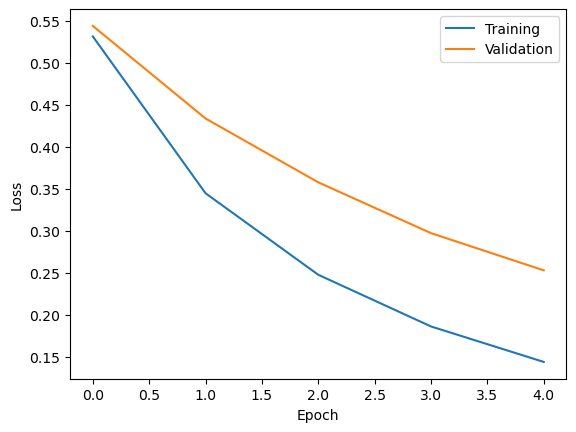

In [ ]:
plt.plot(mobilenetv2_tuned_model_history.history['loss'], label="Training")
plt.plot(mobilenetv2_tuned_model_history.history['val_loss'], label ="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

plt.show()

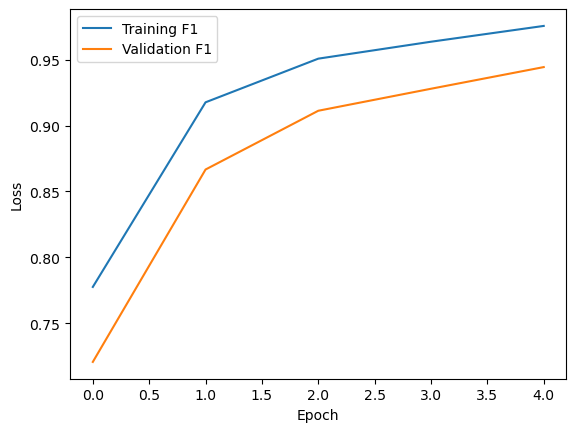

In [ ]:
plt.plot(mobilenetv2_tuned_model_history.history["f1"], label="Training F1")
plt.plot(mobilenetv2_tuned_model_history.history["val_f1"], label="Validation F1")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [ ]:
comparsion_table = pd.DataFrame({
    "Model": ["Custom_Model", "ResNet50", "VGG16", "VGG16_Aug", "EfficientnetB0", "MobilenetV2", "MobilenetV2_tuned"],
    "Accuracy": [custom_model_results["accuracy"], resnet50_results["accuracy"], vgg16_results["accuracy"], vgg16_aug_model_results["accuracy"], efficientnetb0_results["accuracy"], mobilenetv2_results["accuracy"], mobilenetv2_tuned_results["accuracy"]],
    "Recall": [custom_model_results["recall"], resnet50_results["recall"], vgg16_results["recall"], vgg16_aug_model_results["recall"], efficientnetb0_results["recall"], mobilenetv2_results["recall"], mobilenetv2_tuned_results["recall"]],
    "Precision": [custom_model_results["precision"], resnet50_results["precision"], vgg16_results["precision"], vgg16_aug_model_results["precision"], efficientnetb0_results["precision"], mobilenetv2_results["precision"], mobilenetv2_tuned_results["precision"]],
    "ROC_AUC": [custom_model_results["roc_auc"], resnet50_results["roc_auc"], vgg16_results["roc_auc"], vgg16_aug_model_results["roc_auc"], efficientnetb0_results["roc_auc"], mobilenetv2_results["roc_auc"], mobilenetv2_tuned_results["roc_auc"]],
    "PR_AUC": [custom_model_results["pr_auc"], resnet50_results["pr_auc"], vgg16_results["pr_auc"], vgg16_aug_model_results["pr_auc"], efficientnetb0_results["pr_auc"], mobilenetv2_results["pr_auc"], mobilenetv2_tuned_results["pr_auc"]],
    "File_Size_MB": [custom_model_file_size, resnet50_file_size, vgg16_file_size, vgg16_aug_file_size, efficientnetb0_file_size, mobilenetv2_file_size, mobilenetv2_tuned_file_size],
    "Parameters": [custom_model_params, resnet50_params, vgg16_params, vgg16_aug_params, efficientnetb0_params, mobilenetv2_params, mobilenetv2_tuned_params]
})

In [ ]:
comparsion_table.to_csv("../data/comparsion.csv")

In [ ]:
import os

os.environ["KERAS_BACKEND"] = "tensorflow"

import numpy as np
import tensorflow as tf
import keras

# Display
from IPython.display import Image, display
import matplotlib as mpl
import matplotlib.pyplot as plt


In [ ]:
model_builder = keras.applications.xception.Xception
img_size = (224, 224)
preprocess_input = keras.applications.xception.preprocess_input
decode_predictions = keras.applications.xception.decode_predictions

last_conv_layer_name = "block14_sepconv2_act"

# The local path to our target image
img_path = keras.utils.get_file(
    "african_elephant.jpg", "https://i.imgur.com/Bvro0YD.png"
)

display(Image(img_path))


In [ ]:
def get_img_array(img_path, size):
    # `img` is a PIL image of size 299x299
    img = keras.utils.load_img(img_path, target_size=size)
    # `array` is a float32 Numpy array of shape (299, 299, 3)
    array = keras.utils.img_to_array(img)
    # We add a dimension to transform our array into a "batch"
    # of size (1, 299, 299, 3)
    array = np.expand_dims(array, axis=0)
    return array


def make_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index=None):
    # First, we create a model that maps the input image to the activations
    # of the last conv layer as well as the output predictions
    grad_model = keras.models.Model(
        model.inputs, [model.get_layer(last_conv_layer_name).output, model.output]
    )

    # Then, we compute the gradient of the top predicted class for our input image
    # with respect to the activations of the last conv layer
    with tf.GradientTape() as tape:
        last_conv_layer_output, preds = grad_model(img_array)
        if pred_index is None:
            pred_index = tf.argmax(preds[0])
        class_channel = preds[:, pred_index]

    # This is the gradient of the output neuron (top predicted or chosen)
    # with regard to the output feature map of the last conv layer
    grads = tape.gradient(class_channel, last_conv_layer_output)

    # This is a vector where each entry is the mean intensity of the gradient
    # over a specific feature map channel
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    # We multiply each channel in the feature map array
    # by "how important this channel is" with regard to the top predicted class
    # then sum all the channels to obtain the heatmap class activation
    last_conv_layer_output = last_conv_layer_output[0]
    heatmap = last_conv_layer_output @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    # For visualization purpose, we will also normalize the heatmap between 0 & 1
    heatmap = tf.maximum(heatmap, 0) / tf.math.reduce_max(heatmap)
    return heatmap.numpy()


In [ ]:
# Prepare image
img_array = preprocess_input(get_img_array(img_path, size=img_size))

# Make model
model = model_builder(weights="imagenet")

# Remove last layer's softmax
model.layers[-1].activation = None

# Print what the top predicted class is
preds = model.predict(img_array)
print("Predicted:", decode_predictions(preds, top=1)[0])

# Generate class activation heatmap
heatmap = make_gradcam_heatmap(img_array, model, last_conv_layer_name)

# Display heatmap
plt.matshow(heatmap)
plt.show()


In [ ]:
def save_and_display_gradcam(img_path, heatmap, cam_path="cam.jpg", alpha=0.4):
    # Load the original image
    img = keras.utils.load_img(img_path)
    img = keras.utils.img_to_array(img)

    # Rescale heatmap to a range 0-255
    heatmap = np.uint8(255 * heatmap)

    # Use jet colormap to colorize heatmap
    jet = mpl.colormaps["jet"]

    # Use RGB values of the colormap
    jet_colors = jet(np.arange(256))[:, :3]
    jet_heatmap = jet_colors[heatmap]

    # Create an image with RGB colorized heatmap
    jet_heatmap = keras.utils.array_to_img(jet_heatmap)
    jet_heatmap = jet_heatmap.resize((img.shape[1], img.shape[0]))
    jet_heatmap = keras.utils.img_to_array(jet_heatmap)

    # Superimpose the heatmap on original image
    superimposed_img = jet_heatmap * alpha + img
    superimposed_img = keras.utils.array_to_img(superimposed_img)

    # Save the superimposed image
    superimposed_img.save(cam_path)

    # Display Grad CAM
    display(Image(cam_path))


save_and_display_gradcam(img_path, heatmap)
